In [1]:

!pip install -q torchaudio librosa soundfile scikit-learn matplotlib seaborn

import torch
import torchaudio
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

print("PyTorch version:", torch.__version__)
print("TorchAudio version:", torchaudio.__version__)

print("Libraries imported successfully!")


PyTorch version: 2.14.1+cpu
TorchAudio version: 2.11.0+cpu
Libraries imported successfully!


In [4]:

import os

os.makedirs("./data", exist_ok=True)

print("Data folder created successfully!")


Data folder created successfully!


In [5]:

from torchaudio.datasets import YESNO

dataset = YESNO(
    root="./data",
    download=True
)

print("Dataset downloaded successfully!")
print("Number of recordings:", len(dataset))


100%|██████████| 4.49M/4.49M [00:01<00:00, 2.43MB/s]


Dataset downloaded successfully!
Number of recordings: 60


In [6]:

waveform, sample_rate, labels = dataset[0]

print("Waveform shape:", waveform.shape)
print("Sample rate:", sample_rate)
print("Labels:", labels)
print("Number of labels:", len(labels))


Waveform shape: torch.Size([1, 50800])
Sample rate: 8000
Labels: [0, 0, 0, 0, 1, 1, 1, 1]
Number of labels: 8


In [7]:

waveform, sample_rate, labels = dataset[0]

print("Waveform shape:", waveform.shape)
print("Sample rate:", sample_rate)
print("Labels:", labels)
print("Number of labels:", len(labels))


Waveform shape: torch.Size([1, 50800])
Sample rate: 8000
Labels: [0, 0, 0, 0, 1, 1, 1, 1]
Number of labels: 8


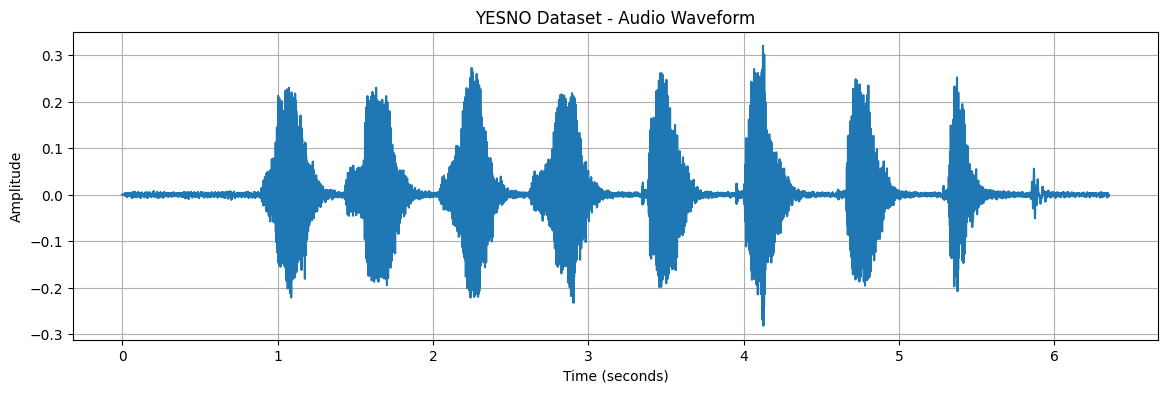

In [9]:

import matplotlib.pyplot as plt
import torch

# Convert waveform to numpy
audio = waveform.squeeze().numpy()

# Create time axis
time = torch.arange(len(audio)).numpy() / sample_rate

# Plot waveform
plt.figure(figsize=(14, 4))
plt.plot(time, audio)

plt.title("YESNO Dataset - Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


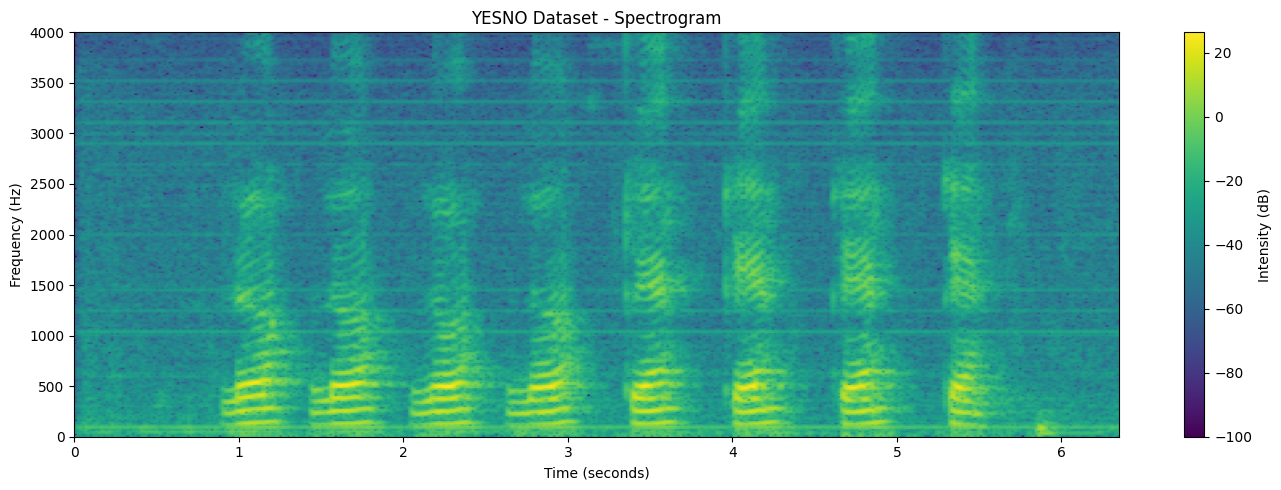

In [10]:

import torchaudio
import matplotlib.pyplot as plt

# Create spectrogram transform
spec_transform = torchaudio.transforms.Spectrogram(
    n_fft=512,
    hop_length=128
)

# Apply transform to waveform
spectrogram = spec_transform(waveform)

# Convert amplitude to decibels
spec_db = torchaudio.transforms.AmplitudeToDB()(spectrogram)

# Plot spectrogram
plt.figure(figsize=(14, 5))

plt.imshow(
    spec_db.squeeze().numpy(),
    origin="lower",
    aspect="auto",
    extent=[
        0,
        waveform.shape[1] / sample_rate,
        0,
        sample_rate / 2
    ],
    cmap="viridis"
)

plt.title("YESNO Dataset - Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")
plt.colorbar(label="Intensity (dB)")
plt.tight_layout()
plt.show()


MFCC shape: torch.Size([1, 13, 397])


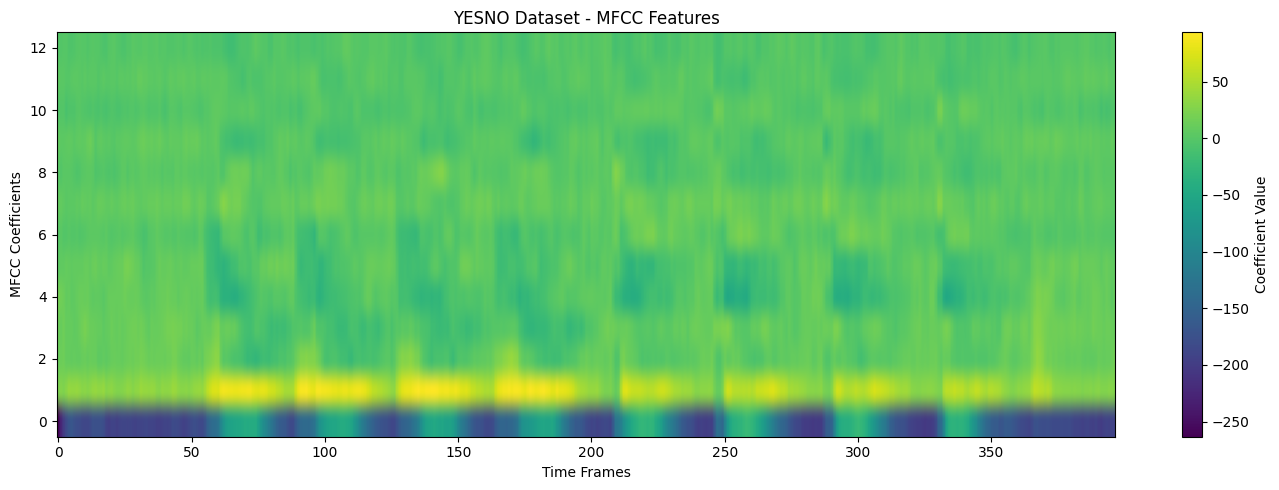

In [11]:

import torchaudio
import matplotlib.pyplot as plt

# Create MFCC transform
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=sample_rate,
    n_mfcc=13,
    melkwargs={
        "n_fft": 512,
        "hop_length": 128,
        "n_mels": 40
    }
)

# Extract MFCC features
mfcc_features = mfcc_transform(waveform)

print("MFCC shape:", mfcc_features.shape)

# Visualize MFCC
plt.figure(figsize=(14, 5))

plt.imshow(
    mfcc_features.squeeze().numpy(),
    origin="lower",
    aspect="auto",
    cmap="viridis"
)

plt.title("YESNO Dataset - MFCC Features")
plt.xlabel("Time Frames")
plt.ylabel("MFCC Coefficients")
plt.colorbar(label="Coefficient Value")
plt.tight_layout()
plt.show()


RMS shape: (397,)
First 10 RMS values: [0.00099808 0.00128523 0.00177307 0.00235877 0.00257044 0.00273943
 0.00281208 0.00252617 0.00245533 0.00254122]


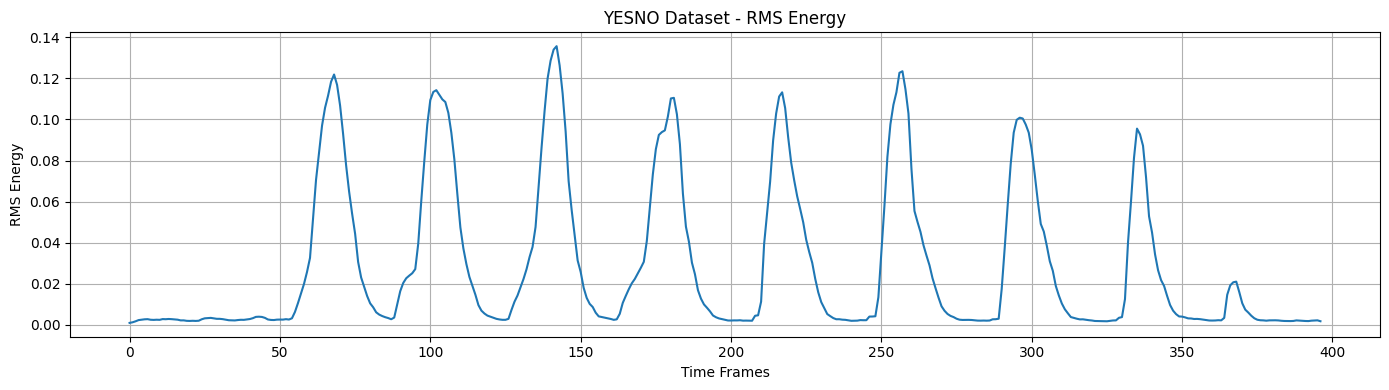

In [12]:

import librosa
import numpy as np
import matplotlib.pyplot as plt

# Extract RMS energy
rms = librosa.feature.rms(
    y=audio,
    frame_length=512,
    hop_length=128
)[0]

print("RMS shape:", rms.shape)
print("First 10 RMS values:", rms[:10])

# Plot RMS energy
plt.figure(figsize=(14, 4))

plt.plot(rms)

plt.title("YESNO Dataset - RMS Energy")
plt.xlabel("Time Frames")
plt.ylabel("RMS Energy")
plt.grid(True)
plt.tight_layout()
plt.show()


ZCR shape: (397,)
First 10 ZCR values: [0.04492188 0.078125   0.11914062 0.12890625 0.15625    0.13085938
 0.11132812 0.09960938 0.07617188 0.08007812]


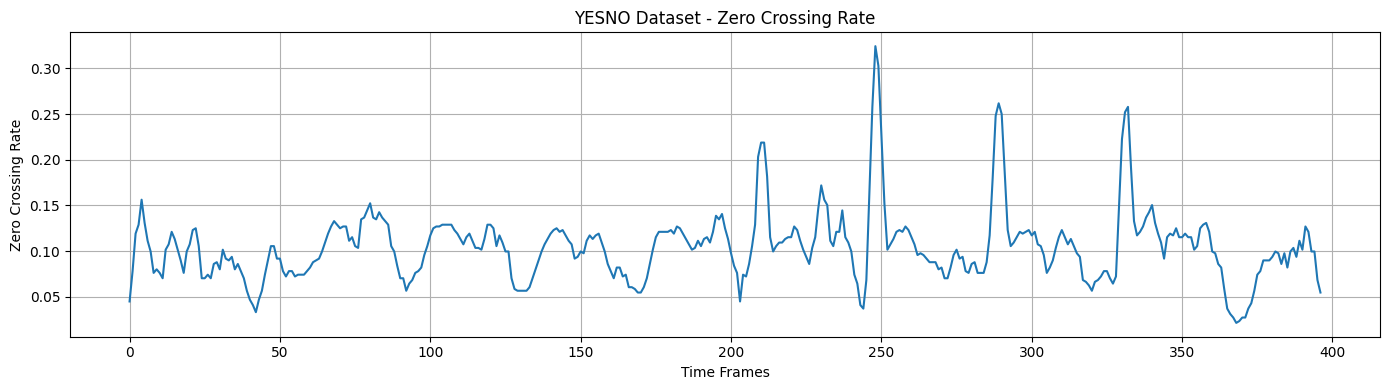

In [13]:

# Extract Zero Crossing Rate
zcr = librosa.feature.zero_crossing_rate(
    y=audio,
    frame_length=512,
    hop_length=128
)[0]

print("ZCR shape:", zcr.shape)
print("First 10 ZCR values:", zcr[:10])

# Plot ZCR
plt.figure(figsize=(14, 4))

plt.plot(zcr)

plt.title("YESNO Dataset - Zero Crossing Rate")
plt.xlabel("Time Frames")
plt.ylabel("Zero Crossing Rate")
plt.grid(True)

plt.tight_layout()
plt.show()


In [14]:

import numpy as np

# Convert MFCC into frame-based format
mfcc_matrix = mfcc_features.squeeze().numpy().T

# Combine all acoustic features
feature_matrix = np.column_stack([
    mfcc_matrix,
    rms,
    zcr
])

print("MFCC shape:", mfcc_matrix.shape)
print("RMS shape:", rms.shape)
print("ZCR shape:", zcr.shape)

print("Combined feature matrix shape:", feature_matrix.shape)
print("Total features per frame:", feature_matrix.shape[1])


MFCC shape: (397, 13)
RMS shape: (397,)
ZCR shape: (397,)
Combined feature matrix shape: (397, 15)
Total features per frame: 15


In [15]:

from collections import Counter

all_labels = []

for i in range(len(dataset)):
    waveform_i, sample_rate_i, labels_i = dataset[i]
    all_labels.extend(labels_i)

label_counts = Counter(all_labels)

print("Total utterance labels:", len(all_labels))
print("Label distribution:", label_counts)
print("Label 0 count:", label_counts[0])
print("Label 1 count:", label_counts[1])


Total utterance labels: 480
Label distribution: Counter({1: 251, 0: 229})
Label 0 count: 229
Label 1 count: 251


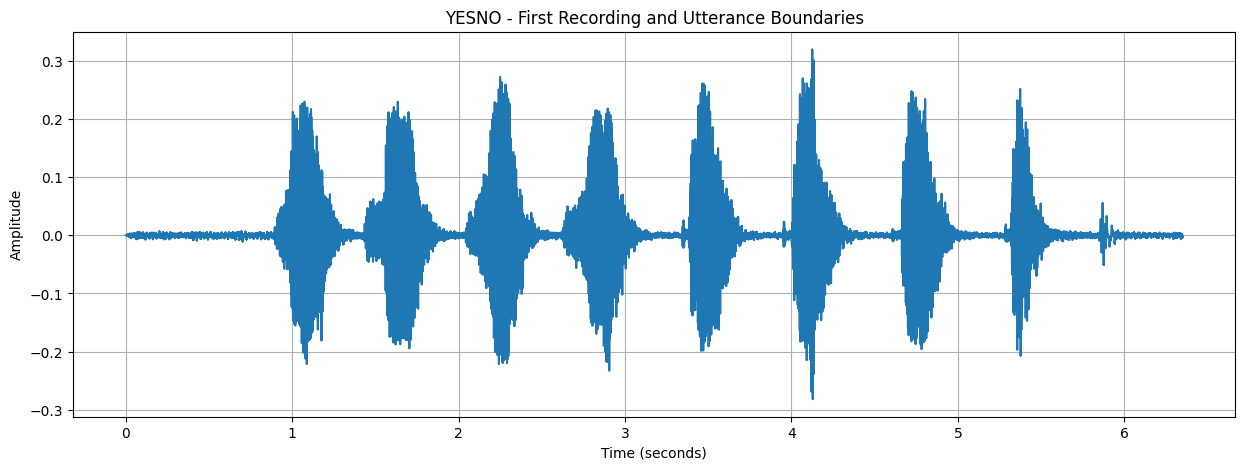

Labels: [0, 0, 0, 0, 1, 1, 1, 1]
Recording duration: 6.35


In [16]:

import matplotlib.pyplot as plt
import numpy as np

# Load the first recording
waveform, sample_rate, labels = dataset[0]

audio = waveform.squeeze().numpy()

time = np.arange(len(audio)) / sample_rate

# Plot the complete recording
plt.figure(figsize=(15, 5))

plt.plot(time, audio)

plt.title("YESNO - First Recording and Utterance Boundaries")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.show()

print("Labels:", labels)
print("Recording duration:", len(audio) / sample_rate)


Detected segments: 9

Segment boundaries:
Segment 1: 0.896s - 1.312s
Segment 2: 1.424s - 1.872s
Segment 3: 2.048s - 2.480s
Segment 4: 2.624s - 3.088s
Segment 5: 3.360s - 3.712s
Segment 6: 3.984s - 4.336s
Segment 7: 4.640s - 4.992s
Segment 8: 5.296s - 5.552s
Segment 9: 5.840s - 5.936s


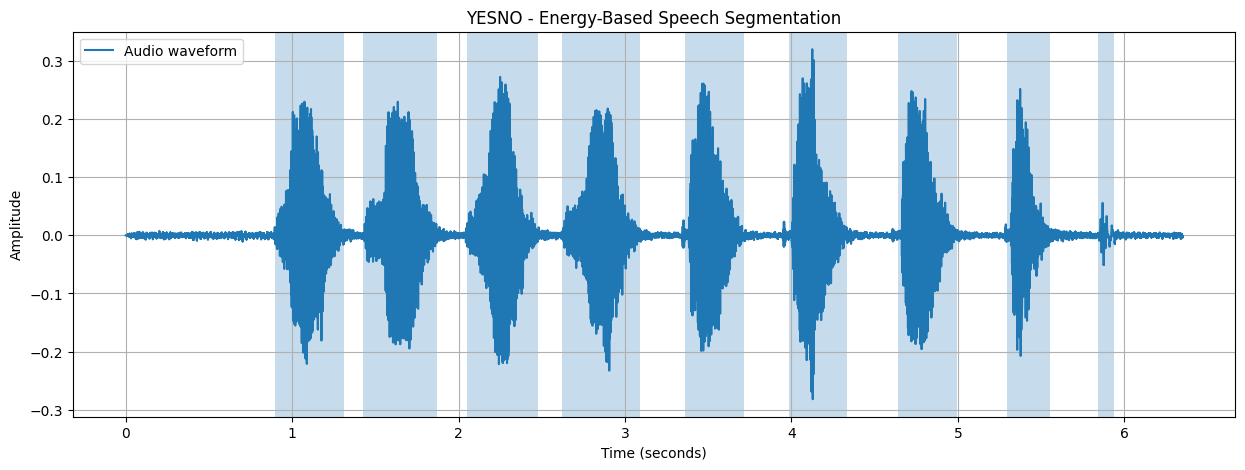

In [17]:

import librosa
import matplotlib.pyplot as plt
import numpy as np

# Detect non-silent intervals
intervals = librosa.effects.split(
    audio,
    top_db=25,
    frame_length=512,
    hop_length=128
)

print("Detected segments:", len(intervals))
print("\nSegment boundaries:")

for i, (start, end) in enumerate(intervals):
    start_time = start / sample_rate
    end_time = end / sample_rate

    print(
        f"Segment {i+1}: "
        f"{start_time:.3f}s - {end_time:.3f}s"
    )

# Visualize detected segments
plt.figure(figsize=(15, 5))
plt.plot(time, audio, label="Audio waveform")

for start, end in intervals:
    plt.axvspan(
        start / sample_rate,
        end / sample_rate,
        alpha=0.25
    )

plt.title("YESNO - Energy-Based Speech Segmentation")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()


In [18]:

# Filter very short detected segments

min_duration = 0.15

filtered_intervals = []

for start, end in intervals:
    duration = (end - start) / sample_rate

    if duration >= min_duration:
        filtered_intervals.append((start, end))

print("Original segments:", len(intervals))
print("Filtered segments:", len(filtered_intervals))

print("\nFiltered segment boundaries:")

for i, (start, end) in enumerate(filtered_intervals):
    print(
        f"Segment {i+1}: "
        f"{start/sample_rate:.3f}s - "
        f"{end/sample_rate:.3f}s"
    )


Original segments: 9
Filtered segments: 8

Filtered segment boundaries:
Segment 1: 0.896s - 1.312s
Segment 2: 1.424s - 1.872s
Segment 3: 2.048s - 2.480s
Segment 4: 2.624s - 3.088s
Segment 5: 3.360s - 3.712s
Segment 6: 3.984s - 4.336s
Segment 7: 4.640s - 4.992s
Segment 8: 5.296s - 5.552s


In [23]:
# Match each segment with its label

for i, (start, end) in enumerate(filtered_intervals):
    label = labels[i].item() if hasattr(labels[i], "item") else labels[i]
    label_name = "YES" if label == 1 else "NO"

    print(f"Segment {i+1}: {label_name}")

Segment 1: NO
Segment 2: NO
Segment 3: NO
Segment 4: NO
Segment 5: YES
Segment 6: YES
Segment 7: YES
Segment 8: YES


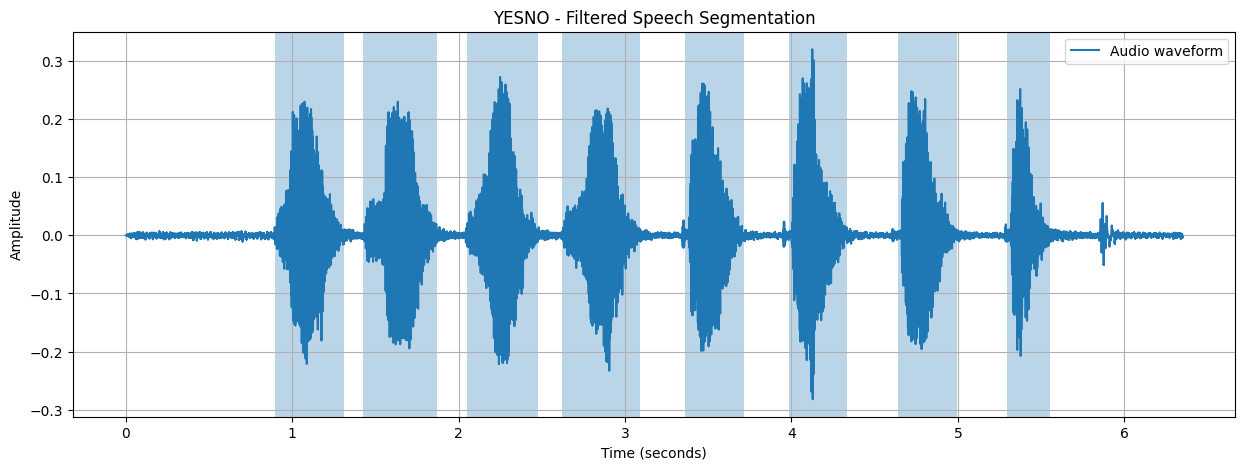

In [19]:

plt.figure(figsize=(15, 5))

plt.plot(time, audio, label="Audio waveform")

for start, end in filtered_intervals:
    plt.axvspan(
        start / sample_rate,
        end / sample_rate,
        alpha=0.3
    )

plt.title("YESNO - Filtered Speech Segmentation")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()


In [20]:

from IPython.display import Audio, display

# Check each detected segment
for i, (start, end) in enumerate(filtered_intervals):

    segment_audio = audio[start:end]
    label = labels[i]

    label_name = "YES" if label == 1 else "NO"

    print(f"Segment {i+1} | Label: {label_name}")

    display(
        Audio(
            segment_audio,
            rate=sample_rate
        )
    )


Segment 1 | Label: NO


Segment 2 | Label: NO


Segment 3 | Label: NO


Segment 4 | Label: NO


Segment 5 | Label: YES


Segment 6 | Label: YES


Segment 7 | Label: YES


Segment 8 | Label: YES


In [21]:

import numpy as np
import torch
import librosa

X = []
y = []
groups = []
skipped_recordings = []

min_duration = 0.15

for recording_id in range(len(dataset)):

    waveform_i, sr_i, labels_i = dataset[recording_id]
    audio_i = waveform_i.squeeze().numpy()

    # Detect candidate speech intervals
    intervals_i = librosa.effects.split(
        audio_i,
        top_db=25,
        frame_length=512,
        hop_length=128
    )

    # Remove very short intervals
    valid_intervals = [
        (start, end)
        for start, end in intervals_i
        if (end - start) / sr_i >= min_duration
    ]

    # Verify number of segments and labels
    if len(valid_intervals) != 8 or len(labels_i) != 8:
        skipped_recordings.append(
            (recording_id, len(valid_intervals), len(labels_i))
        )
        continue

    # Extract features from each utterance
    for segment_id, (start, end) in enumerate(valid_intervals):

        segment = audio_i[start:end]
        segment_tensor = torch.tensor(
            segment, dtype=torch.float32
        ).unsqueeze(0)

        # MFCC: 13 coefficients, averaged over frames
        mfcc_values = mfcc_transform(segment_tensor)
        mfcc_mean = mfcc_values.squeeze(0).mean(dim=1).numpy()

        # RMS Energy
        rms_values = librosa.feature.rms(
            y=segment,
            frame_length=512,
            hop_length=128
        )[0]
        rms_mean = np.mean(rms_values)

        # Zero Crossing Rate
        zcr_values = librosa.feature.zero_crossing_rate(
            y=segment,
            frame_length=512,
            hop_length=128
        )[0]
        zcr_mean = np.mean(zcr_values)

        # Combine 15 features
        feature_vector = np.concatenate([
            mfcc_mean,
            [rms_mean, zcr_mean]
        ])

        X.append(feature_vector)
        y.append(int(labels_i[segment_id]))
        groups.append(recording_id)

X = np.array(X)
y = np.array(y)
groups = np.array(groups)

print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Unique recordings processed:", len(np.unique(groups)))
print("Skipped recordings:", skipped_recordings)
print("Total skipped:", len(skipped_recordings))


Feature matrix shape: (368, 15)
Labels shape: (368,)
Unique recordings processed: 46
Skipped recordings: [(6, 6, 8), (7, 7, 8), (13, 6, 8), (21, 7, 8), (23, 9, 8), (28, 7, 8), (29, 9, 8), (35, 7, 8), (41, 7, 8), (42, 2, 8), (49, 3, 8), (55, 7, 8), (56, 9, 8), (57, 5, 8)]
Total skipped: 14


Skipped recordings inspection

Recording ID: 6
Detected segments: 6
Expected labels: 8


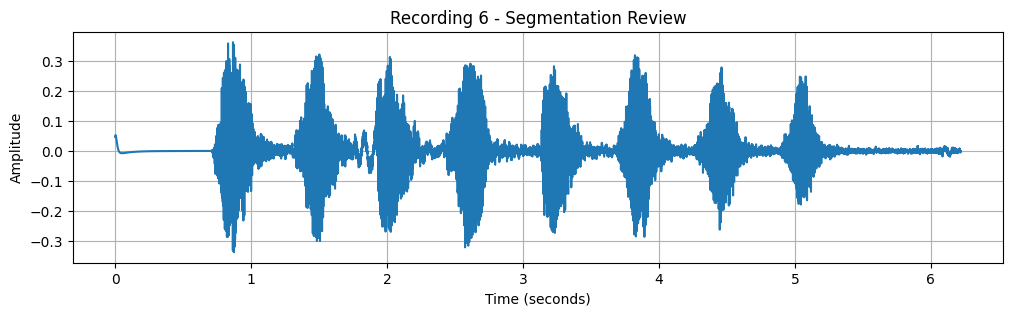


Recording ID: 7
Detected segments: 7
Expected labels: 8


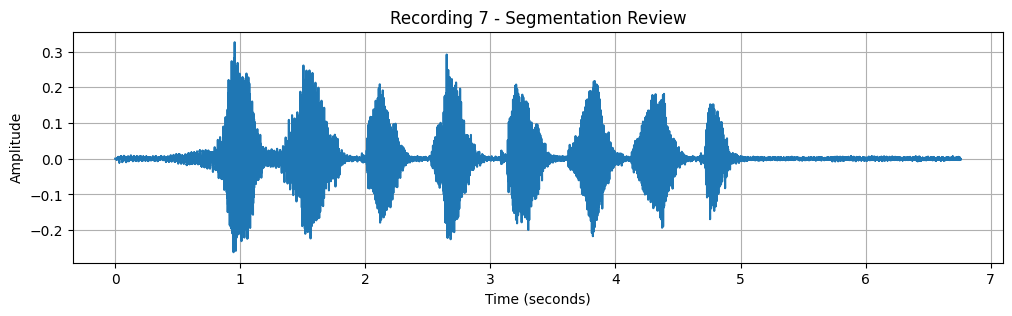


Recording ID: 13
Detected segments: 6
Expected labels: 8


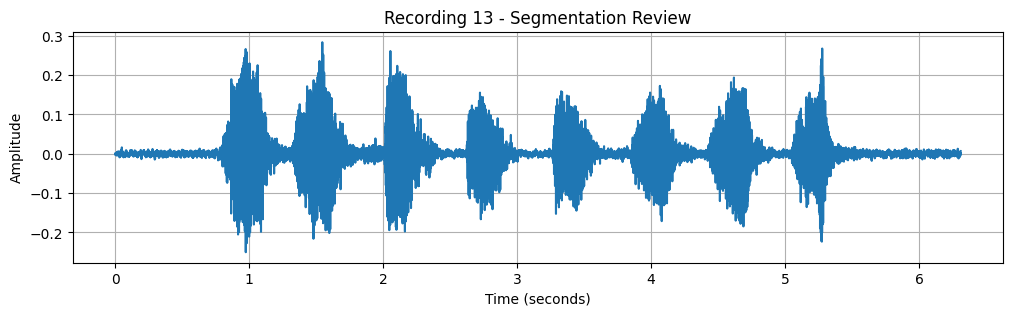


Recording ID: 21
Detected segments: 7
Expected labels: 8


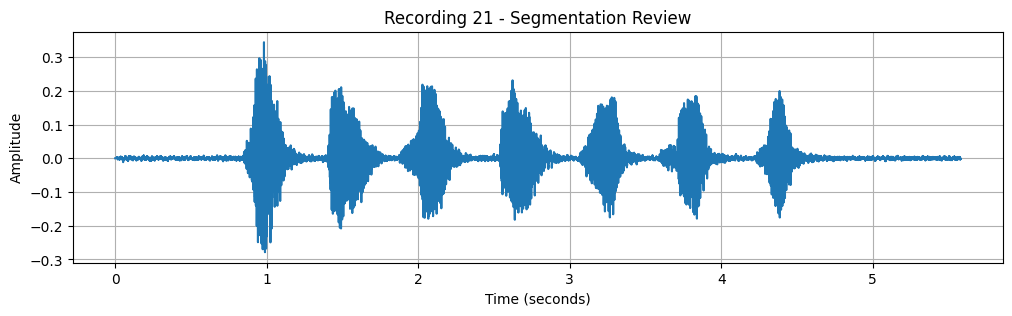


Recording ID: 23
Detected segments: 9
Expected labels: 8


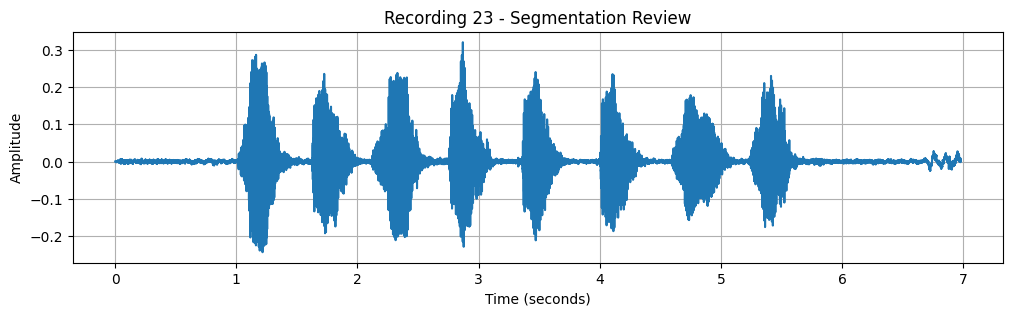


Recording ID: 28
Detected segments: 7
Expected labels: 8


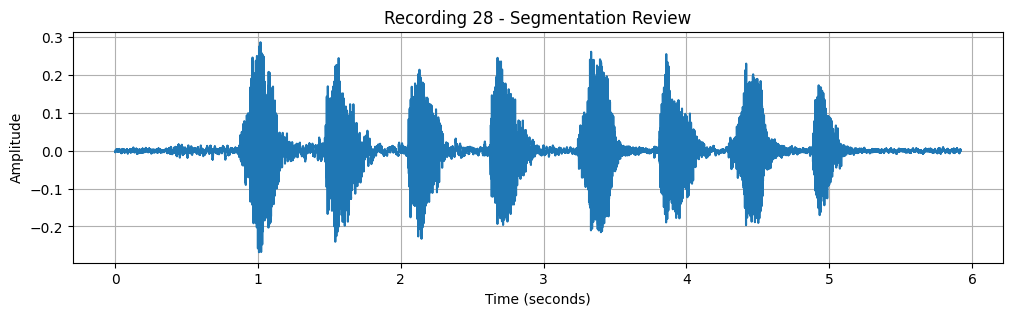


Recording ID: 29
Detected segments: 9
Expected labels: 8


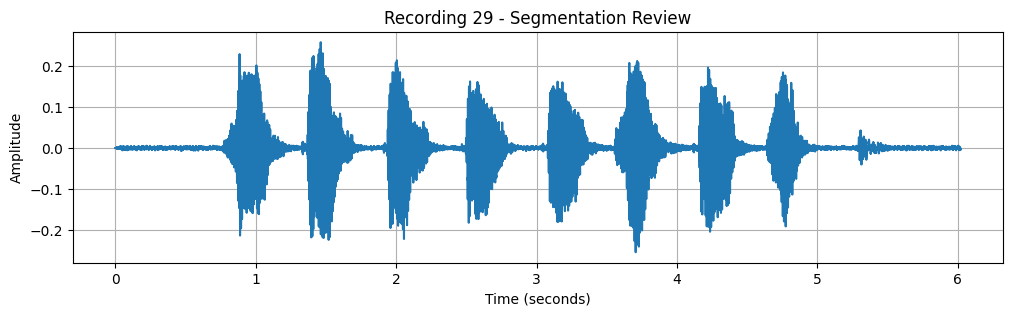


Recording ID: 35
Detected segments: 7
Expected labels: 8


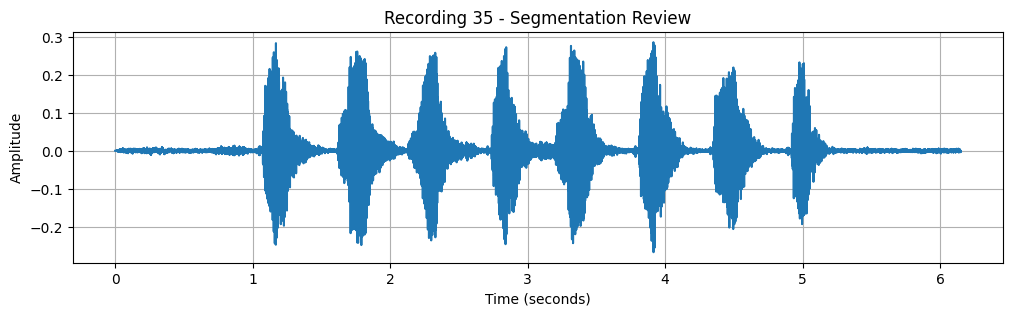


Recording ID: 41
Detected segments: 7
Expected labels: 8


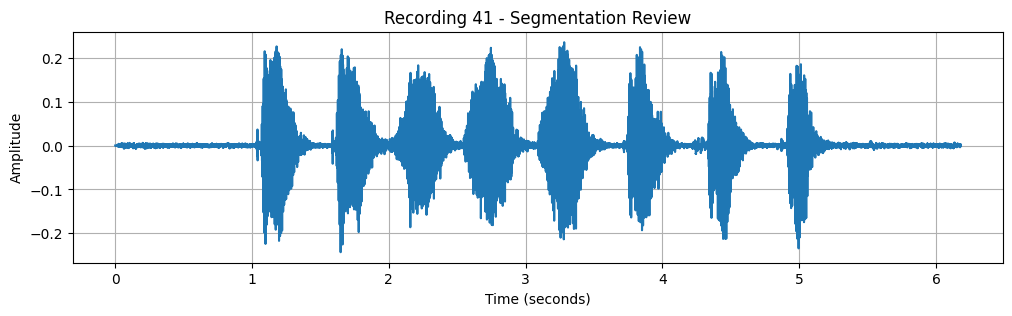


Recording ID: 42
Detected segments: 2
Expected labels: 8


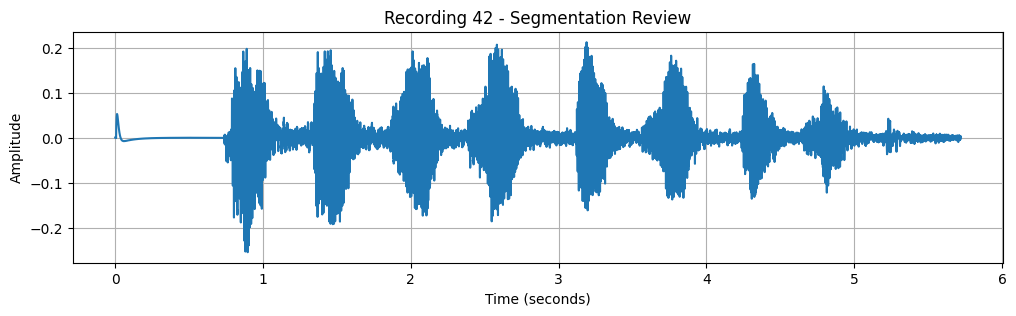


Recording ID: 49
Detected segments: 3
Expected labels: 8


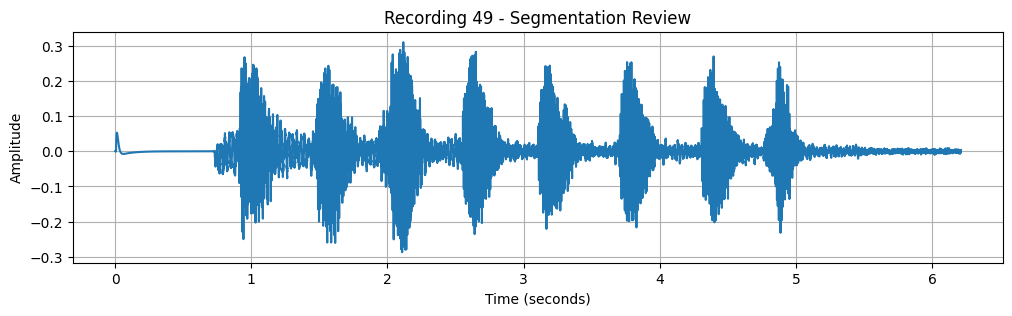


Recording ID: 55
Detected segments: 7
Expected labels: 8


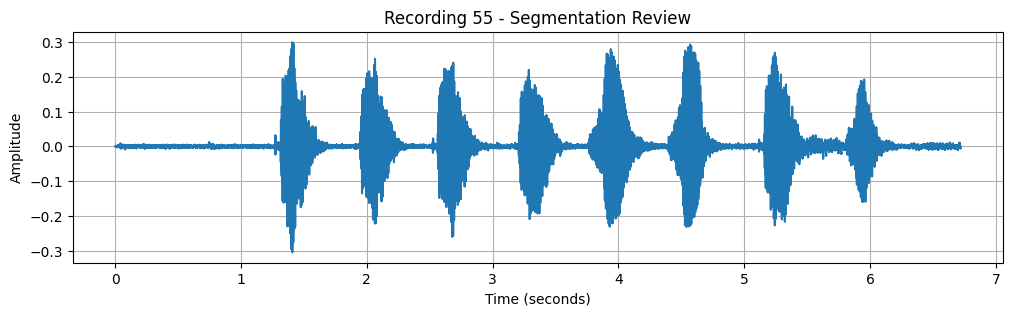


Recording ID: 56
Detected segments: 9
Expected labels: 8


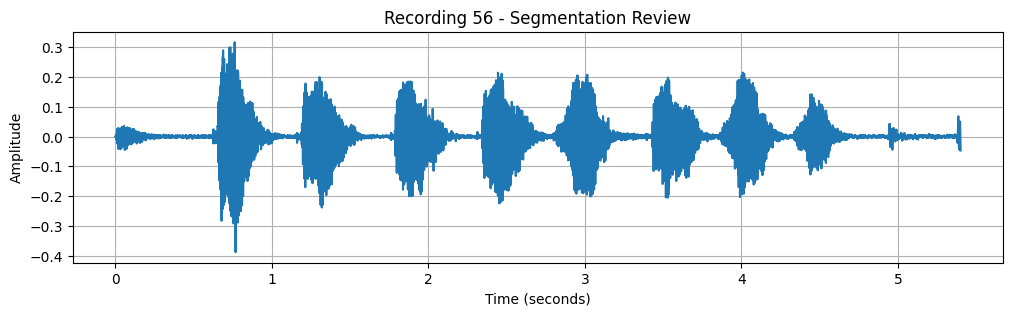


Recording ID: 57
Detected segments: 5
Expected labels: 8


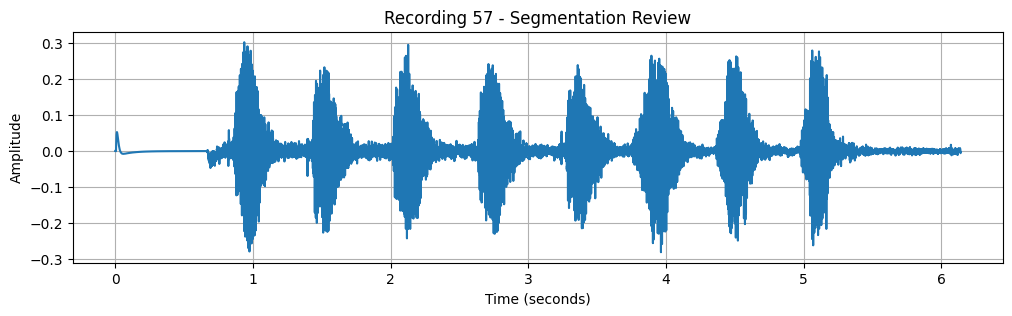

In [22]:

print("Skipped recordings inspection")

for recording_id, detected, expected in skipped_recordings:

    waveform_i, sr_i, labels_i = dataset[recording_id]

    audio_i = waveform_i.squeeze().numpy()

    print("\nRecording ID:", recording_id)
    print("Detected segments:", detected)
    print("Expected labels:", expected)

    plt.figure(figsize=(12, 3))

    plt.plot(
        np.arange(len(audio_i)) / sr_i,
        audio_i
    )

    plt.title(f"Recording {recording_id} - Segmentation Review")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.show()


Selected top_db: 10
Detected segments: 8


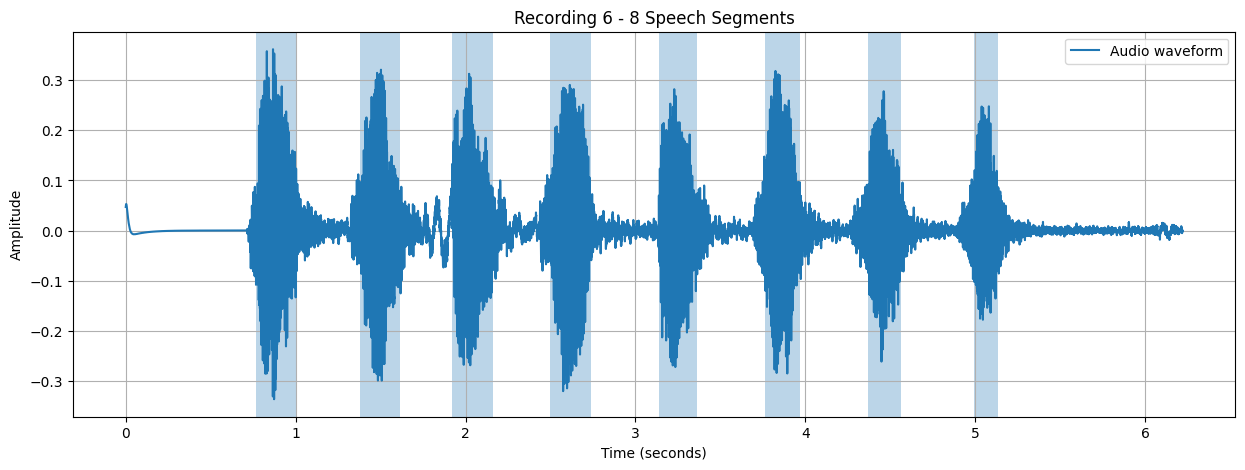

In [24]:
import librosa
import matplotlib.pyplot as plt
import numpy as np

# Select recording 6
recording_id = 6
waveform, sr, labels = dataset[recording_id]

audio = waveform.squeeze().numpy()

# Find a threshold that detects exactly 8 segments
best_result = None

for top_db in range(10, 51):
    intervals = librosa.effects.split(
        audio,
        top_db=top_db,
        frame_length=512,
        hop_length=128
    )

    if len(intervals) == 8:
        best_result = (top_db, intervals)
        break

if best_result is not None:
    top_db, intervals = best_result
    print("Selected top_db:", top_db)
    print("Detected segments:", len(intervals))

    time = np.arange(len(audio)) / sr

    plt.figure(figsize=(15, 5))
    plt.plot(time, audio, label="Audio waveform")

    for start, end in intervals:
        plt.axvspan(start / sr, end / sr, alpha=0.3)

    plt.title(f"Recording {recording_id} - 8 Speech Segments")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.legend()
    plt.show()

else:
    print("Could not detect exactly 8 segments automatically.")

In [26]:
# Reload recording 6 and its correct labels
waveform, sr, labels = dataset[recording_id]

labels = np.asarray(labels).reshape(-1)

print("Recording ID:", recording_id)
print("Detected segments:", len(intervals))
print("Expected labels:", len(labels))

if len(intervals) == len(labels):
    for i, (start, end) in enumerate(intervals):
        label = int(labels[i])
        label_name = "YES" if label == 1 else "NO"

        print(
            f"Segment {i+1}: "
            f"{start/sr:.3f}s - {end/sr:.3f}s | "
            f"Label: {label_name}"
        )
else:
    print("Mismatch: segment count and label count are different.")

Recording ID: 6
Detected segments: 8
Expected labels: 8
Segment 1: 0.768s - 1.008s | Label: NO
Segment 2: 1.376s - 1.616s | Label: NO
Segment 3: 1.920s - 2.160s | Label: YES
Segment 4: 2.496s - 2.736s | Label: NO
Segment 5: 3.136s - 3.360s | Label: YES
Segment 6: 3.760s - 3.968s | Label: NO
Segment 7: 4.368s - 4.560s | Label: NO
Segment 8: 4.992s - 5.136s | Label: NO


In [27]:
recording_id = 7

waveform, sr, labels = dataset[recording_id]
audio = waveform.squeeze().numpy()

best_result = None

for top_db in range(10, 51):
    intervals = librosa.effects.split(
        audio,
        top_db=top_db,
        frame_length=512,
        hop_length=128
    )

    if len(intervals) == 8:
        best_result = (top_db, intervals)
        break

if best_result is not None:
    top_db, intervals = best_result
    labels = np.asarray(labels).reshape(-1)

    print("Recording ID:", recording_id)
    print("Selected top_db:", top_db)
    print("Detected segments:", len(intervals))
    print("Expected labels:", len(labels))

    for i, (start, end) in enumerate(intervals):
        label_name = "YES" if labels[i] == 1 else "NO"
        print(f"Segment {i+1}: {start/sr:.3f}s - {end/sr:.3f}s | {label_name}")
else:
    print("Could not detect exactly 8 segments.")

Recording ID: 7
Selected top_db: 10
Detected segments: 8
Expected labels: 8
Segment 1: 0.880s - 1.136s | NO
Segment 2: 1.408s - 1.712s | NO
Segment 3: 2.048s - 2.240s | YES
Segment 4: 2.608s - 2.800s | NO
Segment 5: 3.152s - 3.392s | YES
Segment 6: 3.712s - 3.936s | NO
Segment 7: 4.224s - 4.448s | NO
Segment 8: 4.736s - 4.848s | YES


In [28]:
recording_id = 13

waveform, sr, labels = dataset[recording_id]
audio = waveform.squeeze().numpy()

best_result = None

for top_db in range(10, 51):
    intervals = librosa.effects.split(
        audio,
        top_db=top_db,
        frame_length=512,
        hop_length=128
    )

    if len(intervals) == 8:
        best_result = (top_db, intervals)
        break

if best_result is not None:
    top_db, intervals = best_result
    labels = np.asarray(labels).reshape(-1)

    print("Recording ID:", recording_id)
    print("Selected top_db:", top_db)
    print("Detected segments:", len(intervals))
    print("Expected labels:", len(labels))

    for i, (start, end) in enumerate(intervals):
        label_name = "YES" if labels[i] == 1 else "NO"
        print(f"Segment {i+1}: {start/sr:.3f}s - {end/sr:.3f}s | {label_name}")
else:
    print("Could not detect exactly 8 segments.")

Recording ID: 13
Selected top_db: 10
Detected segments: 8
Expected labels: 8
Segment 1: 0.848s - 1.136s | NO
Segment 2: 1.360s - 1.680s | NO
Segment 3: 2.016s - 2.256s | YES
Segment 4: 2.640s - 2.880s | YES
Segment 5: 3.280s - 3.520s | YES
Segment 6: 3.920s - 4.160s | NO
Segment 7: 4.480s - 4.752s | NO
Segment 8: 5.088s - 5.328s | NO


In [29]:
recording_id = 21

waveform, sr, labels = dataset[recording_id]
audio = waveform.squeeze().numpy()

best_result = None

for top_db in range(10, 51):
    intervals = librosa.effects.split(
        audio,
        top_db=top_db,
        frame_length=512,
        hop_length=128
    )

    if len(intervals) == 8:
        best_result = (top_db, intervals)
        break

if best_result is not None:
    top_db, intervals = best_result
    labels = np.asarray(labels).reshape(-1)

    print("Recording ID:", recording_id)
    print("Selected top_db:", top_db)
    print("Detected segments:", len(intervals))
    print("Expected labels:", len(labels))

    for i, (start, end) in enumerate(intervals):
        label_name = "YES" if labels[i] == 1 else "NO"
        print(f"Segment {i+1}: {start/sr:.3f}s - {end/sr:.3f}s | {label_name}")
else:
    print("Could not detect exactly 8 segments.")

Recording ID: 21
Selected top_db: 31
Detected segments: 8
Expected labels: 8
Segment 1: 0.832s - 1.264s | NO
Segment 2: 1.376s - 1.792s | YES
Segment 3: 1.872s - 2.352s | NO
Segment 4: 2.512s - 2.960s | YES
Segment 5: 3.056s - 3.488s | NO
Segment 6: 3.584s - 4.048s | NO
Segment 7: 4.112s - 4.128s | NO
Segment 8: 4.224s - 4.640s | NO


In [30]:
recording_id = 23

waveform, sr, labels = dataset[recording_id]
audio = waveform.squeeze().numpy()

best_result = None

for top_db in range(10, 51):
    intervals = librosa.effects.split(
        audio,
        top_db=top_db,
        frame_length=512,
        hop_length=128
    )

    if len(intervals) == 8:
        best_result = (top_db, intervals)
        break

if best_result is not None:
    top_db, intervals = best_result
    labels = np.asarray(labels).reshape(-1)

    print("Recording ID:", recording_id)
    print("Selected top_db:", top_db)
    print("Detected segments:", len(intervals))
    print("Expected labels:", len(labels))

    for i, (start, end) in enumerate(intervals):
        label_name = "YES" if labels[i] == 1 else "NO"

        print(
            f"Segment {i+1}: "
            f"{start/sr:.3f}s - {end/sr:.3f}s | "
            f"Label: {label_name}"
        )

else:
    print("Could not detect exactly 8 segments.")

Recording ID: 23
Selected top_db: 10
Detected segments: 8
Expected labels: 8
Segment 1: 1.088s - 1.328s | Label: NO
Segment 2: 1.632s - 1.856s | Label: YES
Segment 3: 2.224s - 2.464s | Label: NO
Segment 4: 2.768s - 2.976s | Label: YES
Segment 5: 3.376s - 3.568s | Label: YES
Segment 6: 4.016s - 4.208s | Label: YES
Segment 7: 4.688s - 4.960s | Label: NO
Segment 8: 5.312s - 5.536s | Label: NO


Recording ID: 24
Selected top_db: 10
Detected segments: 8
Expected labels: 8
Segment 1: 0.976s - 1.184s | Label: NO
Segment 2: 1.552s - 1.792s | Label: YES
Segment 3: 2.176s - 2.384s | Label: YES
Segment 4: 2.784s - 2.976s | Label: NO
Segment 5: 3.328s - 3.520s | Label: NO
Segment 6: 3.920s - 4.160s | Label: YES
Segment 7: 4.528s - 4.752s | Label: YES
Segment 8: 5.152s - 5.312s | Label: NO


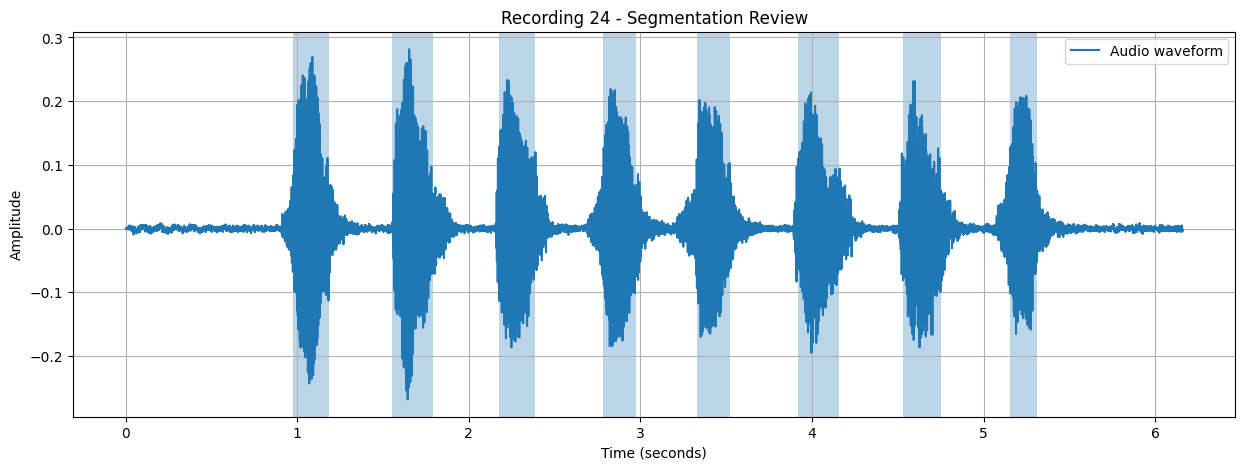

In [31]:
# Inspect Recording 24

recording_id = 24

waveform, sr, labels = dataset[recording_id]
audio_i = waveform.squeeze().numpy()

# Detect speech segments
intervals = librosa.effects.split(
    audio_i,
    top_db=10,
    frame_length=512,
    hop_length=128
)

print("Recording ID:", recording_id)
print("Selected top_db: 10")
print("Detected segments:", len(intervals))
print("Expected labels:", len(labels))

if len(intervals) == len(labels):

    for i, (start, end) in enumerate(intervals):

        label = labels[i].item() if hasattr(labels[i], "item") else labels[i]
        label_name = "YES" if label == 1 else "NO"

        print(
            f"Segment {i+1}: "
            f"{start/sr:.3f}s - {end/sr:.3f}s | "
            f"Label: {label_name}"
        )

else:
    print("Mismatch: segment count and label count are different.")

# Plot waveform
time_i = np.arange(len(audio_i)) / sr

plt.figure(figsize=(15, 5))
plt.plot(time_i, audio_i, label="Audio waveform")

for start, end in intervals:
    plt.axvspan(start/sr, end/sr, alpha=0.3)

plt.title(f"Recording {recording_id} - Segmentation Review")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

In [32]:

import numpy as np
import librosa
import matplotlib.pyplot as plt

# Process all recordings in YESNO dataset

all_segments = []
all_labels = []
all_recording_ids = []
all_boundaries = []
skipped_recordings = []

top_db_values = [10, 12, 15, 18, 20, 22, 25, 28, 30, 31, 35, 40]

print("Starting YESNO dataset processing...")
print("Total recordings:", len(dataset))

for recording_id in range(len(dataset)):

    waveform, sr, labels = dataset[recording_id]
    audio = waveform.squeeze().numpy()

    labels_list = [
        int(x.item()) if hasattr(x, "item") else int(x)
        for x in labels
    ]

    selected_intervals = None
    selected_top_db = None

    # Find a threshold that detects exactly 8 segments
    for top_db in top_db_values:

        intervals = librosa.effects.split(
            audio,
            top_db=top_db,
            frame_length=512,
            hop_length=128
        )

        if len(intervals) == len(labels_list):
            selected_intervals = intervals
            selected_top_db = top_db
            break

    # Skip recordings where segmentation does not match labels
    if selected_intervals is None:
        skipped_recordings.append(recording_id)
        print(
            f"Recording {recording_id}: "
            f"Skipped - could not match segment count"
        )
        continue

    # Save each speech segment and its label
    for i, (start, end) in enumerate(selected_intervals):

        segment = audio[start:end]

        all_segments.append(segment)
        all_labels.append(labels_list[i])
        all_recording_ids.append(recording_id)

        all_boundaries.append((
            start / sr,
            end / sr
        ))

    print(
        f"Recording {recording_id}: "
        f"{len(selected_intervals)} segments | "
        f"top_db = {selected_top_db}"
    )

# Final results
print("\n========== FINAL RESULTS ==========")
print("Total recordings:", len(dataset))
print("Successfully processed:", len(set(all_recording_ids)))
print("Skipped recordings:", len(skipped_recordings))
print("Total speech segments:", len(all_segments))
print("Total YES:", all_labels.count(1))
print("Total NO:", all_labels.count(0))
print("Skipped recording IDs:", skipped_recordings)


Starting YESNO dataset processing...
Total recordings: 60
Recording 0: 8 segments | top_db = 10
Recording 1: 8 segments | top_db = 10
Recording 2: 8 segments | top_db = 10
Recording 3: 8 segments | top_db = 10
Recording 4: 8 segments | top_db = 10
Recording 5: 8 segments | top_db = 10
Recording 6: 8 segments | top_db = 10
Recording 7: 8 segments | top_db = 10
Recording 8: 8 segments | top_db = 10
Recording 9: 8 segments | top_db = 10
Recording 10: 8 segments | top_db = 10
Recording 11: 8 segments | top_db = 10
Recording 12: 8 segments | top_db = 10
Recording 13: 8 segments | top_db = 10
Recording 14: 8 segments | top_db = 10
Recording 15: 8 segments | top_db = 10
Recording 16: 8 segments | top_db = 10
Recording 17: 8 segments | top_db = 10
Recording 18: 8 segments | top_db = 10
Recording 19: 8 segments | top_db = 10
Recording 20: 8 segments | top_db = 10
Recording 21: 8 segments | top_db = 31
Recording 22: 8 segments | top_db = 10
Recording 23: 8 segments | top_db = 10
Recording 24: 8 

In [33]:

# Feature Extraction: MFCC, RMS, ZCR, Spectral Centroid

import numpy as np
import librosa

X = []
y = []
groups = []

for segment, label, recording_id in zip(
    all_segments, all_labels, all_recording_ids
):

    # MFCC features
    mfcc = librosa.feature.mfcc(
        y=segment,
        sr=sr,
        n_mfcc=13
    )

    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    # RMS Energy
    rms = librosa.feature.rms(y=segment)[0]
    rms_features = [np.mean(rms), np.std(rms)]

    # Zero Crossing Rate
    zcr = librosa.feature.zero_crossing_rate(segment)[0]
    zcr_features = [np.mean(zcr), np.std(zcr)]

    # Spectral Centroid
    centroid = librosa.feature.spectral_centroid(
        y=segment,
        sr=sr
    )[0]

    centroid_features = [
        np.mean(centroid),
        np.std(centroid)
    ]

    features = np.concatenate([
        mfcc_mean,
        mfcc_std,
        rms_features,
        zcr_features,
        centroid_features
    ])

    X.append(features)
    y.append(label)
    groups.append(recording_id)

X = np.array(X)
y = np.array(y)
groups = np.array(groups)

print("Feature extraction completed!")
print("Feature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Number of features:", X.shape[1])
print("Number of samples:", len(y))
print("YES samples:", np.sum(y == 1))
print("NO samples:", np.sum(y == 0))


/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1920
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1792
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1664
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1024
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1536
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1280
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py

Feature extraction completed!
Feature matrix shape: (480, 32)
Labels shape: (480,)
Number of features: 32
Number of samples: 480
YES samples: 251
NO samples: 229


In [34]:

# Feature Extraction - Fixed Version

import numpy as np
import librosa

X = []
y = []
groups = []

for segment, label, recording_id in zip(
    all_segments, all_labels, all_recording_ids
):

    # MFCC
    mfcc = librosa.feature.mfcc(
        y=segment,
        sr=sr,
        n_mfcc=13,
        n_fft=512,
        hop_length=128
    )

    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    # RMS Energy
    rms = librosa.feature.rms(
        y=segment,
        frame_length=512,
        hop_length=128
    )[0]

    rms_features = [np.mean(rms), np.std(rms)]

    # Zero Crossing Rate
    zcr = librosa.feature.zero_crossing_rate(
        segment,
        frame_length=512,
        hop_length=128
    )[0]

    zcr_features = [np.mean(zcr), np.std(zcr)]

    # Spectral Centroid
    centroid = librosa.feature.spectral_centroid(
        y=segment,
        sr=sr,
        n_fft=512,
        hop_length=128
    )[0]

    centroid_features = [
        np.mean(centroid),
        np.std(centroid)
    ]

    features = np.concatenate([
        mfcc_mean,
        mfcc_std,
        rms_features,
        zcr_features,
        centroid_features
    ])

    X.append(features)
    y.append(label)
    groups.append(recording_id)

X = np.array(X)
y = np.array(y)
groups = np.array(groups)

print("Feature extraction completed!")
print("Feature matrix shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of samples:", len(y))
print("YES samples:", np.sum(y == 1))
print("NO samples:", np.sum(y == 0))


/usr/local/lib/python3.13/dist-packages/librosa/core/spectrum.py:266: UserWarning: n_fft=512 is too large for input signal of length=128
  warnings.warn(


Feature extraction completed!
Feature matrix shape: (480, 32)
Number of features: 32
Number of samples: 480
YES samples: 251
NO samples: 229


In [35]:

# Train and Compare Four Classifiers

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Split data by recording ID to prevent data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Define four classifiers
models = {
    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Neural Network (MLP)": make_pipeline(
        StandardScaler(),
        MLPClassifier(
            hidden_layer_sizes=(64, 32),
            max_iter=1000,
            random_state=42
        )
    )
}

results = []

# Train and evaluate
for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0)
    })

# Display comparison
results_df = pd.DataFrame(results)

print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))

print("\nModel Comparison:")
display(results_df.round(4))


Training samples: 384
Testing samples: 96

Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,SVM,1.0,1.0,1.0,1.0
1,Random Forest,1.0,1.0,1.0,1.0
2,KNN,1.0,1.0,1.0,1.0
3,Neural Network (MLP),1.0,1.0,1.0,1.0
